# Suport del contenidor: anàlisi a fatiga (apartat 2)

**Disseny i assaig de màquines (DiAM)** · J.A. Mayugo, UdG

Factors de seguretat estàtic (von Mises) i a fatiga (Goodman modificat amb el criteri de Sines) de l'Acer 1 amb $r=5$ mm, i diagrama de Haigh.

## Llibreries

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.ticker import MultipleLocator

plt.rcParams['svg.fonttype'] = 'none'

## Dades del problema

In [2]:
m_max, m_min = 1000.0, 250.0   # kg, massa del contenidor ple i buit
d_e, d_i = 100.0, 80.0         # mm, diàmetres exterior i interior de l'eix
D = 120.0                      # mm, diàmetre del reforç central
r = 5.0                        # mm, radi d'acord
l1, l2 = 1100.0, 500.0         # mm, distàncies contenidor i cilindre a l'eix de rotació
alpha = np.radians(30)         # angle del pistó respecte la vertical
l_AB, l_CD = 1200.0, 120.0     # mm, longitud de l'eix i del reforç central
g = 9.81                       # m/s2
Sut, Sy = 500.0, 370.0         # MPa, Acer 1
Sep = 0.5*Sut                  # MPa, límit de fatiga estimat

## Funcions

In [3]:
def K_t_rodo_flexio(D_d, r_d):
    """K_t d'un rodó a flexió amb canvi de diàmetre (D_d = D/d, r_d = r/d)."""
    return (0.632 + 0.377*D_d**(-4.4)
            + r_d**(-0.5)*np.sqrt((-0.14 - 0.363*D_d**2 + 0.503*D_d**4)
                                  /(1 - 2.39*D_d**2 + 3.368*D_d**4)))

def K_t_rodo_torsio(D_d, r_d):
    """K_ts d'un rodó a torsió amb canvi de diàmetre (D_d = D/d, r_d = r/d)."""
    return (0.78 + 0.2*D_d**(-10)
            + r_d**(-0.46)*np.sqrt((0.002 - 0.125*D_d**2 + 0.123*D_d**4)
                                   /(1 - 2.75*D_d**2 + 2.55*D_d**4)))

def q_sensibilitat_entalla(r, Sut, cisalla=False):
    """Sensibilitat a l'entalla d'un acer (r en mm, Sut en MPa): q (tracció/flexió) o q_s (tallant)."""
    S = Sut/6.9
    r_in = r/25.4
    if cisalla:
        sqr_a = 0.190 - 2.51e-3*S + 1.35e-5*S**2 - 2.67e-8*S**3
    else:
        sqr_a = 0.246 - 3.08e-3*S + 1.51e-5*S**2 - 2.67e-8*S**3
    return 1/(1 + sqr_a/np.sqrt(r_in))

def tensions_principals(sx, tau):
    """Tensions principals (I >= II >= III) d'un estat pla (sx, 0, tau)."""
    c, rad = sx/2, np.hypot(sx/2, tau)
    A, B = c + rad, c - rad
    if B > 0:
        return A, B, 0.0
    if A > 0:
        return A, 0.0, B
    return 0.0, A, B

def von_mises(s1, s2, s3):
    return np.sqrt(2)/2*np.sqrt((s1 - s2)**2 + (s2 - s3)**2 + (s3 - s1)**2)

def Se_modificat(Sut, Sep, d):
    """Límit de fatiga modificat Se = Sep*ka*kb*kc (mecanitzat, flexió i torsió)."""
    ka = 4.51*Sut**(-0.265)
    if d < 2.79:
        kb = (2.79/7.62)**(-0.107)
    elif d <= 51:
        kb = (d/7.62)**(-0.107)
    else:
        kb = 1.51*d**(-0.157)
    kc = 1.0
    return Sep*ka*kb*kc, ka, kb, kc

## Forces internes i propietats de la secció

In [4]:
R = m_min/m_max                                      # reversió de la càrrega
Fp = m_max*g*l1/(l2*np.cos(alpha))                   # N
V = Fp/2                                             # N
L = (l_AB - l_CD)/2 - r                              # mm
M = L*Fp/2                                           # N·mm
T = l1*m_max/2*g                                     # N·mm
I = np.pi*(d_e**4 - d_i**4)/64                       # mm4
J = np.pi*(d_e**4 - d_i**4)/32                       # mm4
print("Forces internes i secció")
print(f"  Fp = {Fp:.1f} N, V = {V:.1f} N, M = {M:.4g} N·mm, T = {T:.4g} N·mm, I = {I:.4g} mm4, J = {J:.4g} mm4")

Forces internes i secció
  Fp = 24920.7 N, V = 12460.4 N, M = 6.666e+06 N·mm, T = 5.396e+06 N·mm, I = 2.898e+06 mm4, J = 5.796e+06 mm4


## Tensions nominals i coeficient de seguretat estàtic (von Mises)

In [5]:
sig_max, tau_max = M*(d_e/2)/I, T*(d_e/2)/J          # MPa
sig_min, tau_min = R*sig_max, R*tau_max
s1, s2, s3 = tensions_principals(sig_max, tau_max)
sig_eqv_max = von_mises(s1, s2, s3)
SF_e = Sy/sig_eqv_max
print("\nFalla estàtica")
print(f"  sigma_M,max = {sig_max:.1f} MPa, tau_T,max = {tau_max:.1f} MPa, sigma_eqv,max = {sig_eqv_max:.1f} MPa")
print(f"  SF_e = {SF_e:.2f}")


Falla estàtica
  sigma_M,max = 115.0 MPa, tau_T,max = 46.5 MPa, sigma_eqv,max = 140.5 MPa
  SF_e = 2.63


## Concentració de tensions (només a les components alternes)

In [6]:
K_t = K_t_rodo_flexio(D/d_e, r/d_e)
K_ts = K_t_rodo_torsio(D/d_e, r/d_e)
q = q_sensibilitat_entalla(r, Sut)
q_s = q_sensibilitat_entalla(r, Sut, cisalla=True)
K_f = 1 + q*(K_t - 1)
K_fs = 1 + q_s*(K_ts - 1)

## Components mitjana i alterna, i criteri de Sines

In [7]:
sig_m_M, tau_m_T = (sig_max + sig_min)/2, (tau_max + tau_min)/2
sig_a_M, tau_a_T = K_f*(sig_max - sig_min)/2, K_fs*(tau_max - tau_min)/2
Im = tensions_principals(sig_m_M, tau_m_T)           # (I, II, III) mitjanes
Ia = tensions_principals(sig_a_M, tau_a_T)           # (I, II, III) alternes
sigma_m = sum(Im)                                    # Sines: suma de les tensions principals mitjanes
sigma_a = von_mises(*Ia)                             # Sines: von Mises de les components alternes
print("\nEstat de tensió cíclica")
print(f"  q = {q:.3f}, K_t = {K_t:.2f}, K_f = {K_f:.2f}, q_s = {q_s:.3f}, K_ts = {K_ts:.2f}, K_fs = {K_fs:.2f}")
print(f"  (sigma_M)m = {sig_m_M:.1f}, (tau_T)m = {tau_m_T:.1f}, (sigma_M)a = {sig_a_M:.1f}, (tau_T)a = {tau_a_T:.1f} MPa")
print(f"  sigma_I,m = {Im[0]:.1f}, sigma_II,m = {Im[1]:.1f}, sigma_III,m = {Im[2]:.1f} MPa")
print(f"  sigma_I,a = {Ia[0]:.1f}, sigma_II,a = {Ia[1]:.1f}, sigma_III,a = {Ia[2]:.1f} MPa")
print(f"  sigma_m (Sines) = {sigma_m:.1f} MPa, sigma_a (von Mises) = {sigma_a:.1f} MPa")


Estat de tensió cíclica
  q = 0.828, K_t = 2.10, K_f = 1.91, q_s = 0.866, K_ts = 1.53, K_fs = 1.46
  (sigma_M)m = 71.9, (tau_T)m = 29.1, (sigma_M)a = 82.3, (tau_T)a = 25.5 MPa
  sigma_I,m = 82.2, sigma_II,m = 0.0, sigma_III,m = -10.3 MPa
  sigma_I,a = 89.5, sigma_II,a = 0.0, sigma_III,a = -7.3 MPa
  sigma_m (Sines) = 71.9 MPa, sigma_a (von Mises) = 93.4 MPa


## Coeficient de seguretat a fatiga (Goodman modificat)

In [8]:
Se, ka, kb, kc = Se_modificat(Sut, Sep, d_e)
SF_f = 1/(sigma_m/Sut + sigma_a/Se)
print("\nFalla a fatiga")
print(f"  ka = {ka:.2f}, kb = {kb:.2f}, kc = {kc:.2f}, Se' = {Sep:.1f} MPa, Se = {Se:.1f} MPa")
print(f"  SF_f = {SF_f:.2f}")


Falla a fatiga
  ka = 0.87, kb = 0.73, kc = 1.00, Se' = 250.0 MPa, Se = 159.2 MPa
  SF_f = 1.37


## Diagrama de Haigh

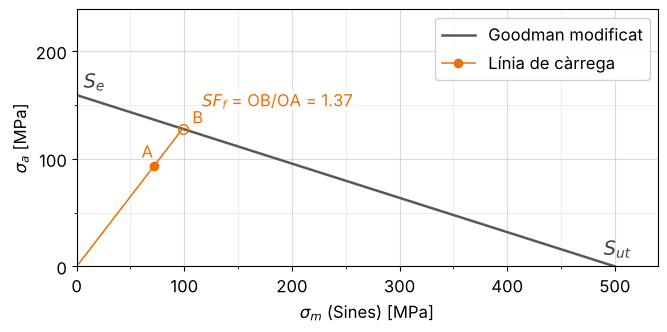

In [9]:
# Línia de càrrega: de l'origen (O) al punt de treball (A), prolongada fins a la recta de Goodman (B).
# SF_f = OB/OA.
OR = '#E8710A'   # taronja
BL = '#6FA3DC'   # blau pastel
plt.rcParams.update({'font.size': 12})
fig, ax = plt.subplots(figsize=(7.5, 3.8))
sm = np.array([0.0, Sut])
ax.plot(sm, Se*(1 - sm/Sut), '-', color='0.35', linewidth=1.8)                   # Goodman modificat
ax.plot([0, SF_f*sigma_m], [0, SF_f*sigma_a], '-', color=OR, linewidth=1.1)      # línia de càrrega O-B
ax.plot(sigma_m, sigma_a, 'o', color=OR, markersize=6)                           # A
ax.plot(SF_f*sigma_m, SF_f*sigma_a, 'o', color=OR, markerfacecolor='none', markersize=7)   # B
ax.annotate('A', (sigma_m, sigma_a), textcoords='offset points', xytext=(-9, 6), color=OR, fontsize=12)
ax.annotate('B', (SF_f*sigma_m, SF_f*sigma_a), textcoords='offset points', xytext=(7, 4), color=OR, fontsize=12)
ax.annotate(f'$SF_f$ = OB/OA = {SF_f:.2f}', (SF_f*sigma_m, SF_f*sigma_a), textcoords='offset points',
            xytext=(14, 16), color=OR, fontsize=12,
            bbox=dict(fc='white', ec='none', pad=0.6, alpha=0.85))
ax.annotate('$S_e$', (0, Se), textcoords='offset points', xytext=(5, 5), color='0.25', fontsize=14)
ax.annotate('$S_{ut}$', (Sut, 0), textcoords='offset points', xytext=(-8, 8), color='0.25', fontsize=14)
handles = [Line2D([], [], color='0.35', linewidth=1.8, label='Goodman modificat'),
           Line2D([], [], color=OR, marker='o', linewidth=1.1, markersize=6, label='Línia de càrrega')]
ax.set_xlim(0, 1.08*Sut); ax.set_ylim(0, 1.5*Se)
ax.set_aspect('equal', adjustable='box')
ax.xaxis.set_major_locator(MultipleLocator(100)); ax.xaxis.set_minor_locator(MultipleLocator(50))
ax.yaxis.set_major_locator(MultipleLocator(100)); ax.yaxis.set_minor_locator(MultipleLocator(50))
ax.set_xlabel('$\\sigma_m$ (Sines) [MPa]'); ax.set_ylabel('$\\sigma_a$ [MPa]')
ax.legend(handles=handles, loc='upper right', fontsize=12, framealpha=0.9)
ax.grid(True, which='major', alpha=0.45)
ax.grid(True, which='minor', alpha=0.2)
fig.savefig('DiAM_05c_contenidor_Haigh_Fig1.pdf', bbox_inches='tight')
fig.savefig('DiAM_05c_contenidor_Haigh_Fig1.svg', bbox_inches='tight')
plt.show()